In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from load_forecast.db import read_sql

In [3]:
week = read_sql(
    """
    SELECT ts, consumption_mw, forecast_d1_mw
    FROM consumption
    WHERE ts >= %s AND ts < %s
    ORDER BY ts
    """,
    ("2025-01-13 00:00+01", "2025-01-20 00:00+01"),
)
week["ts"] = pd.to_datetime(week["ts"], utc=True).dt.tz_convert("Europe/Paris")
week.head()

,ts,consumption_mw,forecast_d1_mw
0,2025-01-13 00:00:00+01:00,69430,68500
1,2025-01-13 00:30:00+01:00,68709,67400
2,2025-01-13 01:00:00+01:00,66667,66300
3,2025-01-13 01:30:00+01:00,66250,66700
4,2025-01-13 02:00:00+01:00,65849,66400


Consumption is higher on weekdays and lower on nights and week-ends. The RTE forecast is very close to the real consumption 

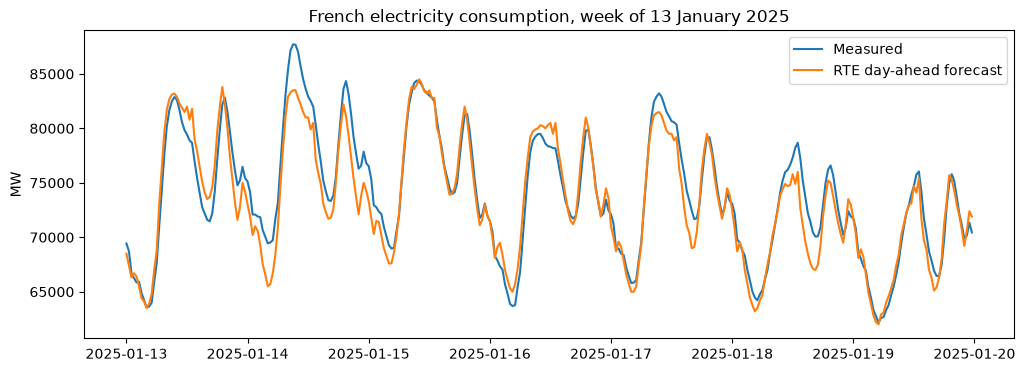

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(week["ts"], week["consumption_mw"], label="Measured")
ax.plot(week["ts"], week["forecast_d1_mw"], label="RTE day-ahead forecast")
ax.set_ylabel("MW")
ax.set_title("French electricity consumption, week of 13 January 2025")
ax.legend()
plt.show()